In [24]:
# pip install pandas openpyxl matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
# Paso 1: Leer archivo Excel
df = pd.read_excel("Ind_Econ_96_Paises.xlsx", sheet_name="Hoja2")

### Paso 2: Separar variables numéricas y nombres de países

In [4]:
# Paso 2: Separar variables numéricas y nombres de países
countries = df["País"]
data = df.iloc[:, 1:].values  # Variables numéricas

In [26]:
df

,País,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11
0,Albania,1.0,30,41,2199,3903,12,94,53,0.0,341,1.2
1,Angola,3.0,124,46,4422,955,6,57,19,0.7,89,0.5
2,Arabia Saudi,4.3,21,13,133540,91019,96,497,1,0.0,4566,13.1
3,Argelia,2.5,34,24,44609,19883,42,180,2,0.8,906,3.0
4,Argentina,1.3,22,31,278431,65962,160,1043,22,0.1,1504,3.5
...,...,...,...,...,...,...,...,...,...,...,...,...
91,Venezuela,2.4,23,33,65382,73116,111,382,52,1.2,2186,5.7
92,Vietnam,2.2,41,49,17634,12270,11,414,26,1.5,101,0.3
93,Yemen,4.2,100,29,4044,2159,12,335,8,0.0,206,0.7
94,Zambia,2.6,109,45,3605,7785,8,186,43,1.1,149,0.3


In [34]:
# Paso 2: Estandarizar los datos
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data) # no lo hagass !!!!


fit_scaler = scaler.fit(data)
## mean_ (x), scale_ (std)

# import pickle
# with open('artefacto_scaler.pkl', 'wb') as archivo:
#     pickle.dump(fit_scaler, archivo)

# #--> llamar al artefacto 
data_scaled= fit_scaler.transform(data)

# ## medias
# #x1, x2, x3  --->  test/oot (muestra fuera de tiempo) OOT
# ## APLICAN AL TRAIN (ARTEFACTOS) --> REPLIQUEN LO MISMO EN EL TEST

In [10]:
# ## TESTEO / OOT
# --> llamar al artefacto "artefacto_scaler.pkl"
# data_scaled= fit_scaler.transform(data)

### Paso 3: Escalar los datos

In [35]:
# Paso 3: Ajustar PCA
pca = PCA()
components = pca.fit_transform(data_scaled)

# pca = pca.fit()
# -- GUARDAR PCA 
# components = pca.transform(data_scaled)

In [37]:
pca

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

### Paso 4: Obtener las cargas (loadings) como cruce de variables X vs componentes PC

In [47]:
# Paso 4: Obtener métricas
eigenvalues = pca.explained_variance_
explained_var_ratio = pca.explained_variance_ratio_
cumulative_var_ratio = np.cumsum(explained_var_ratio)

In [ ]:
#S * a = \lambda * a 

In [56]:
matriz_covarianza = np.cov(data_scaled, rowvar=False)

In [66]:
autovectores = pca.components_
autovalores = pca.explained_variance_

#matriz_covarianza @ autovectores[0] # S * a
#autovalores[0] * autovectores[0] # \lambda *a

In [67]:
# Paso 5: Cargas (loadings)
loadings = pd.DataFrame(
    pca.components_.T,
    index=df.columns[1:],
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)
loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
X1,-0.314119,-0.348357,0.073525,-0.440287,0.329721,0.183924,0.162897,0.094820,0.521812,0.346746,0.100628
X2,-0.392395,0.041362,0.177593,-0.133985,-0.083405,0.086564,0.639804,0.323078,-0.290316,-0.389592,-0.174871
X3,0.116546,0.582836,-0.166863,0.058650,-0.186541,-0.168356,0.531087,-0.052099,0.235998,0.428547,0.167868
X4,0.295394,0.176908,0.533430,-0.262482,0.141107,-0.046534,-0.149021,0.449132,-0.369957,0.349115,0.152474
X5,0.258965,0.173564,0.614388,-0.173896,0.075220,-0.028219,0.108275,-0.503439,0.306813,-0.337704,-0.123664
X6,0.446083,0.027191,-0.151772,0.049598,0.054165,-0.024422,-0.000850,0.569751,0.447331,-0.209977,-0.449926
X7,0.092411,-0.320610,0.370243,0.736031,-0.026710,0.309409,0.235767,0.059625,0.083582,0.205618,0.070678
X8,0.005693,0.457427,-0.164803,0.040249,0.415317,0.753565,-0.080604,-0.042754,-0.074385,-0.086712,0.014937
X9,-0.243652,0.154082,0.029614,0.336503,0.732615,-0.508942,0.011233,0.016075,-0.018686,-0.032098,-0.072596
X10,0.415030,-0.232863,-0.206087,-0.067302,0.231004,-0.058065,0.271123,0.050236,-0.043398,-0.361474,0.679125


### Paso 5: Scree Plot estilo R con mejoras visuales

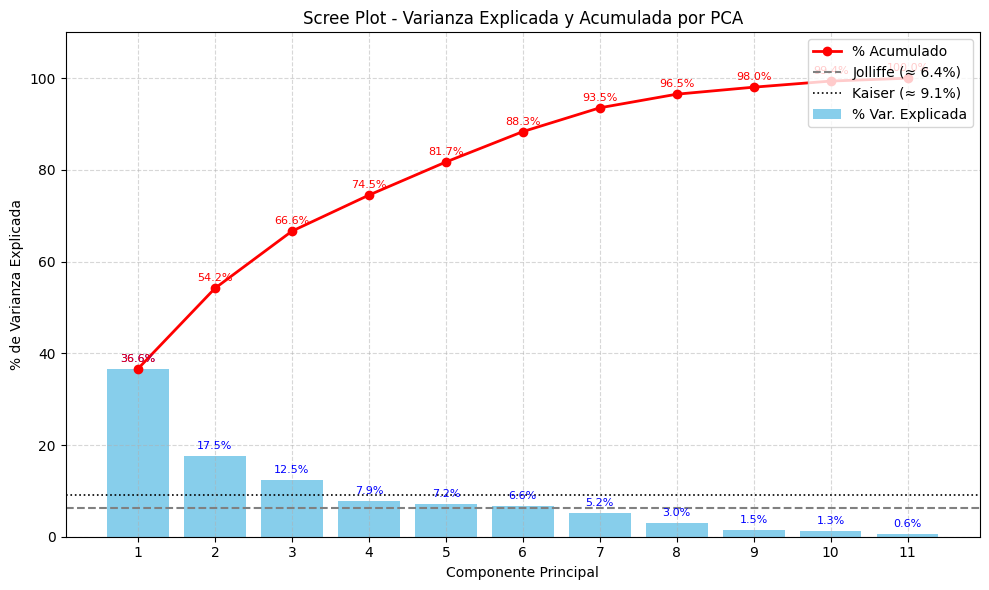

In [15]:
# Paso 5: Scree Plot estilo R
var_exp_pct = explained_var_ratio * 100
cum_var_exp_pct = np.cumsum(var_exp_pct)
components_x = np.arange(1, len(var_exp_pct) + 1)

# Determinar el máximo para ajustar la escala
y_max = max(np.max(var_exp_pct), np.max(cum_var_exp_pct)) + 10

plt.figure(figsize=(10, 6))

# Barras individuales
bars = plt.bar(components_x, var_exp_pct, color='skyblue', label='% Var. Explicada')

# Etiquetas sobre cada barra
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1.5, f"{height:.1f}%", ha='center', fontsize=8, color='blue')

# Línea acumulada
plt.plot(components_x, cum_var_exp_pct, color='red', marker='o', linewidth=2, label='% Acumulado')

# Etiquetas sobre la línea acumulada
for i in range(len(cum_var_exp_pct)):
    plt.text(components_x[i], cum_var_exp_pct[i] + 1.5, f"{cum_var_exp_pct[i]:.1f}%", color='red', ha='center', fontsize=8)

# Líneas de referencia (con etiquetas mejoradas)
jolliffe_pct = 0.7 * 100 / len(var_exp_pct)
kaiser_pct = 1 * 100 / len(var_exp_pct)

plt.axhline(y=jolliffe_pct, color='gray', linestyle='--', linewidth=1.5, label=f'Jolliffe (≈ {jolliffe_pct:.1f}%)')
plt.axhline(y=kaiser_pct, color='black', linestyle=':', linewidth=1.2, label=f'Kaiser (≈ {kaiser_pct:.1f}%)')

# Estética general
plt.title("Scree Plot - Varianza Explicada y Acumulada por PCA")
plt.xlabel("Componente Principal")
plt.ylabel("% de Varianza Explicada")
plt.xticks(components_x)
plt.ylim(0, y_max)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Paso 6: Criterio de Jolliffe

In [16]:
# Paso 6: Criterio de Jolliffe
jolliffe_components = np.where(eigenvalues > 0.7)[0] + 1
print("Componentes retenidos según Jolliffe (eigenvalue > 0.7):", jolliffe_components)

Componentes retenidos según Jolliffe (eigenvalue > 0.7): [1 2 3 4 5 6]


#### ¿Cómo interpretar cada componente?

In [17]:
# Calcular las cargas
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

# Crear DataFrame con los dos primeros componentes
loading_df = pd.DataFrame(loadings[:, :2], index=df.columns[1:], columns=['PC1', 'PC2'])

# Mostrar resultados
print("Cargas corregidas de las variables (PC1, PC2):")
print(loading_df)


Cargas corregidas de las variables (PC1, PC2):
          PC1       PC2
X1  -0.633891 -0.486493
X2  -0.791852  0.057764
X3   0.235190  0.813951
X4   0.596103  0.247059
X5   0.522589  0.242388
X6   0.900193  0.037973
X7   0.186484 -0.447743
X8   0.011488  0.638812
X9  -0.491689  0.215181
X10  0.837527 -0.325201
X11  0.755801 -0.407351


In [68]:
# PC1 = -0.633891 * X1 + (-0.791852) * X2 + .....
# PC2 = ....
# ...
# PC11

In [18]:
for pc in ['PC1', 'PC2']:
    print(f"\n Interpretación de {pc}:")
    top_vars = loading_df[pc].abs().sort_values(ascending=False).head(4)
    for var in top_vars.index:
        signo = "↑" if loading_df.loc[var, pc] > 0 else "↓"
        print(f"- {signo} {var} contribuye fuertemente a {pc}")


 Interpretación de PC1:
- ↑ X6 contribuye fuertemente a PC1
- ↑ X10 contribuye fuertemente a PC1
- ↓ X2 contribuye fuertemente a PC1
- ↑ X11 contribuye fuertemente a PC1

 Interpretación de PC2:
- ↑ X3 contribuye fuertemente a PC2
- ↑ X8 contribuye fuertemente a PC2
- ↓ X1 contribuye fuertemente a PC2
- ↓ X7 contribuye fuertemente a PC2


##### Interpretación de Componentes
| Variable | Descripción                                                              |
|----------|---------------------------------------------------------------------------|
| X1       | Tasa anual de crecimiento de la población                                |
| X2       | Tasa de mortalidad infantil por cada 1000 nacidos vivos                  |
| X3       | Porcentaje de mujeres en la población activa                             |
| X4       | PNB en 1995 (en millones de dólares)                                     |
| X5       | Producción de electricidad (en millones kW/h)                            |
| X6       | Líneas telefónicas por cada 1000 habitantes                              |
| X7       | Consumo de agua per cápita                                               |
| X8       | Proporción de la superficie del país cubierta por bosques                |
| X9       | Proporción de deforestación anual                                        |
| X10      | Consumo de energía per cápita                                            |
| X11      | Emisión de CO₂ per cápita                                                |

Las Variables X2, X6, X10 y X11 son las que más contribuyen en la primera componente, se interpreta como _Indice de riqueza o desarrollo_.
Las Variables X1, X3, X7 y X8 son las que más contribuyen en la segunda componente, se interpreta como _índice de sostenibilidad_

### Paso 7: Gráfico estilo R de países en el espacio PC1 vs PC2

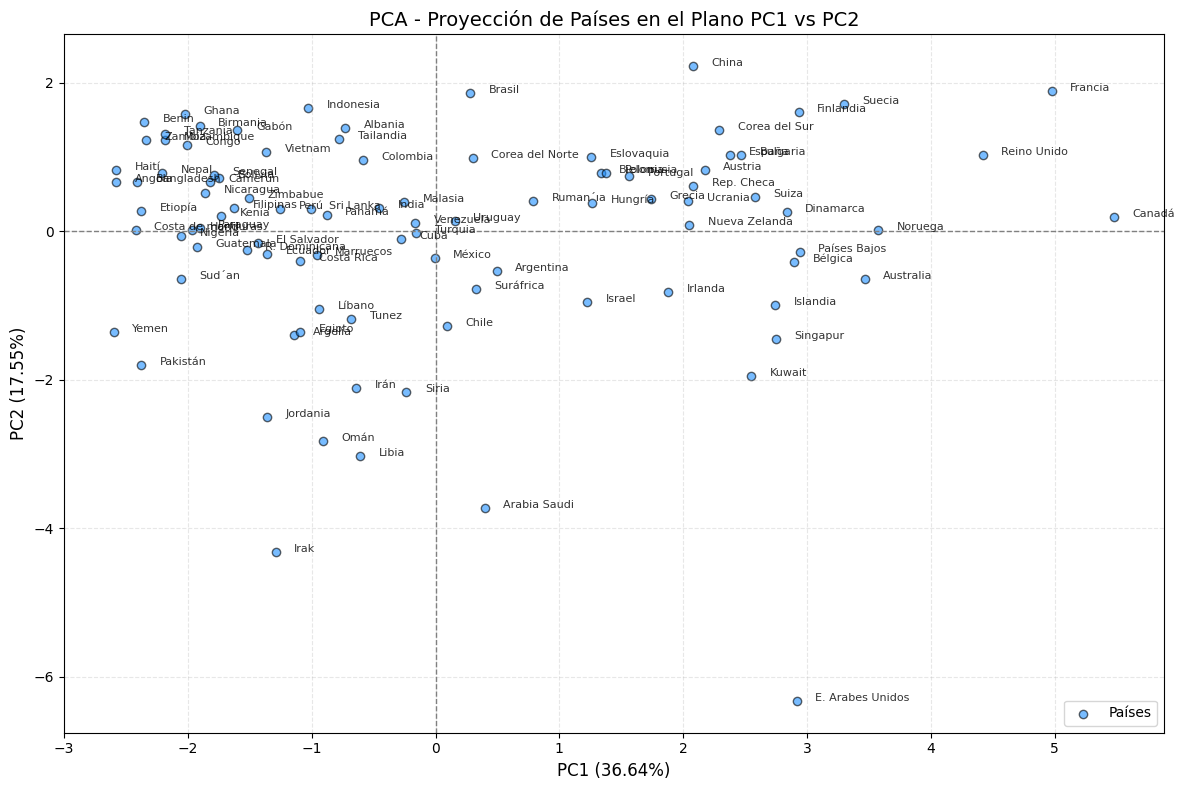

In [19]:
# Paso 7: Gráfico estilo R de países en el espacio PC1 vs PC2
pc1 = components[:, 0]
pc2 = components[:, 1]

plt.figure(figsize=(12, 8))
plt.axhline(0, color='gray', linestyle='--', linewidth=1)  # eje horizontal
plt.axvline(0, color='gray', linestyle='--', linewidth=1)  # eje vertical

# Puntos
plt.scatter(pc1, pc2, alpha=0.6, color='dodgerblue', edgecolors='black', label='Países')

# Etiquetas
for i, name in enumerate(countries):
    plt.text(pc1[i] + 0.15, pc2[i], name, fontsize=8, alpha=0.8)

# Ejes con porcentaje de varianza explicada
plt.xlabel(f"PC1 ({explained_var_ratio[0]*100:.2f}%)", fontsize=12)
plt.ylabel(f"PC2 ({explained_var_ratio[1]*100:.2f}%)", fontsize=12)

# Título y estilo
plt.title("PCA - Proyección de Países en el Plano PC1 vs PC2", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


#### ¿Qué países se asocian más a cada componente?

In [20]:
# Crear DataFrame con las dos primeras componentes
componentes_df = pd.DataFrame(components[:, :2], columns=['PC1', 'PC2'])
componentes_df['País'] = countries

# Ordenar países por cada componente
pc1_sorted = componentes_df.sort_values(by='PC1', ascending=False)
pc2_sorted = componentes_df.sort_values(by='PC2', ascending=False)

# Mostrar los primeros y últimos 8 de PC1
print("Países con mayor y menor score en PC1:")
print(pd.concat([pc1_sorted[['País', 'PC1']].head(8), pc1_sorted[['País', 'PC1']].tail(8)]), "\n")

# Mostrar los primeros y últimos 8 de PC2
print("Países con mayor y menor score en PC2:")
print(pd.concat([pc2_sorted[['País', 'PC2']].head(8), pc2_sorted[['País', 'PC2']].tail(8)]), "\n")




Países con mayor y menor score en PC1:
               País       PC1
15           Canadá  5.479460
36          Francia  4.976956
74      Reino Unido  4.419963
65          Noruega  3.574937
5         Australia  3.464706
82           Suecia  3.296123
42     Países Bajos  2.941124
35        Finlandia  2.932011
9             Benin -2.354767
68         Pakistán -2.376832
33          Etiopía -2.377576
7        Bangladesh -2.409545
20  Costa de marfil -2.423421
1            Angola -2.581830
41            Haití -2.581832
93            Yemen -2.599022 

Países con mayor y menor score en PC2:
                País       PC2
24             China  2.227754
36           Francia  1.892712
12            Brasil  1.870947
82            Suecia  1.716084
46         Indonesia  1.662780
35         Finlandia  1.605099
38             Ghana  1.578746
9              Benin  1.471089
48              Irán -2.105181
79             Siria -2.165205
52          Jordania -2.504545
67              Omán -2.818931
56     

#### Interpretación
Según este índice, Canadá, Francia, Reino Unido, Noruega y Australia serían los países con mayor grado de desarrollo, mientras que Yemen, Haití
y Angola serían los de menor grado. Por otro lado, Irán, Arabia Saudí y Emiratos Árabes son los pa´ıses con un mayor valor en la
segunda componente principal.

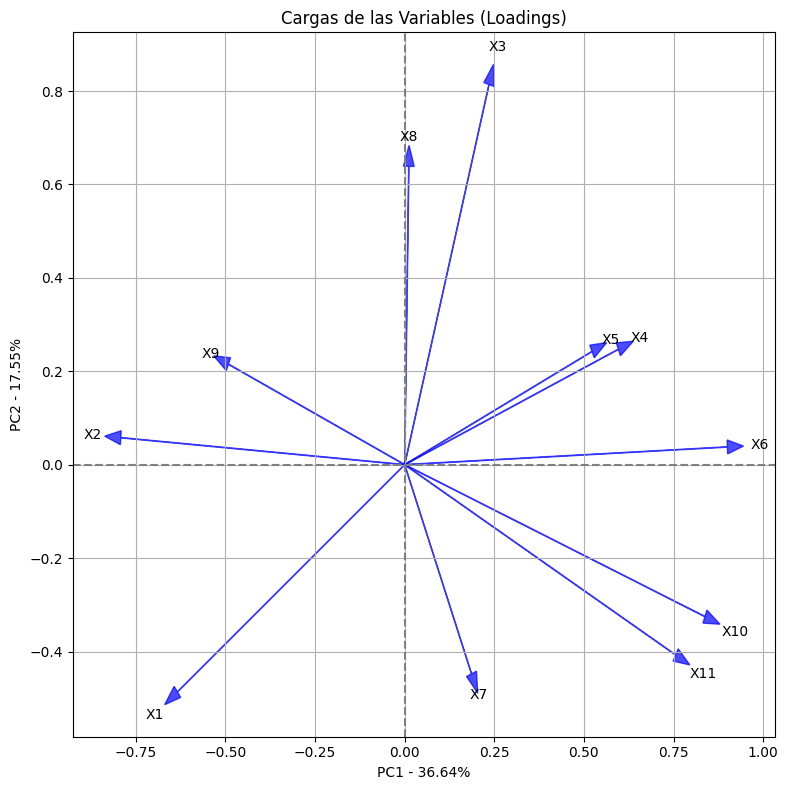

In [21]:
# Paso 8: Gráfico de variables (loadings ampliados con ajuste de signo en PC2)
loadings_scaled = pca.components_.T * np.sqrt(pca.explained_variance_)

# Ajuste del signo de PC2 (si se invirtió previamente)

plt.figure(figsize=(8, 8))
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')

for i, var in enumerate(df.columns[1:]):
    plt.arrow(0, 0, loadings_scaled[i, 0], loadings_scaled[i, 1], head_width=0.03, color='blue', alpha=0.7)
    plt.text(loadings_scaled[i, 0]*1.1, loadings_scaled[i, 1]*1.1, var,
             color='black', ha='center', va='center')

plt.xlabel(f"PC1 - {explained_var_ratio[0]*100:.2f}%")
plt.ylabel(f"PC2 - {explained_var_ratio[1]*100:.2f}%")
plt.title("Cargas de las Variables (Loadings)")
plt.grid(True)
plt.tight_layout()
plt.show()


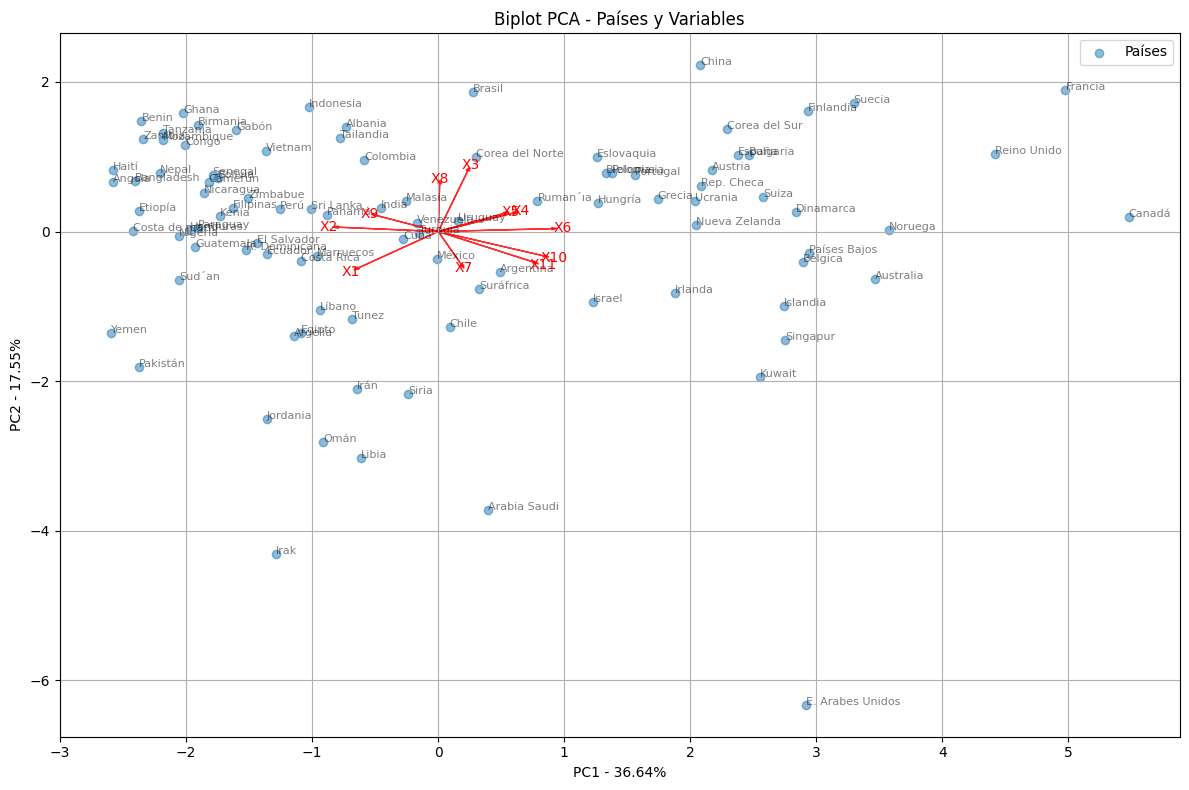

In [22]:
# Paso 9: Biplot (países + variables)
plt.figure(figsize=(12, 8))

# Países
plt.scatter(components[:, 0], components[:, 1], alpha=0.5, label='Países')
for i, name in enumerate(countries):
    plt.text(components[i, 0], components[i, 1], name, fontsize=8, alpha=0.5)

# Variables
for i, var in enumerate(df.columns[1:]):
    plt.arrow(0, 0, loadings_scaled[i, 0], loadings_scaled[i, 1],
              color='red', alpha=0.8, head_width=0.03)
    plt.text(loadings_scaled[i, 0]*1.1, loadings_scaled[i, 1]*1.1, var,
             color='red', ha='center', va='center')

plt.xlabel(f"PC1 - {explained_var_ratio[0]*100:.2f}%")
plt.ylabel(f"PC2 - {explained_var_ratio[1]*100:.2f}%")
plt.title("Biplot PCA - Países y Variables")
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()